# DNN Assignment 2 - Problem 1: RNN, LSTM and GRU on sequences
Run top to bottom (Restart and Run All). Relative paths only: data goes to `../data`, figures to `figures/`, results to `../results.csv`.

**Assumptions:** the Individualisation table was not in the assignment text I had, so hidden size, seeds and the ablation parity are set in the config cell based on last digit of my BITS ID. Main adding-problem runs use gradient clipping (norm 1.0)
for all three models; the ablation in task 5(c) compares against no clipping.

In [ ]:
import os, time, math, random, zipfile, urllib.request
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

# ---------------- CONFIG ----------------
STUDENT_ID    = "2026AK05289"      # Last digit picks the 5(c) ablation. Mine is 9 which is odd so we pick LSTM.
HIDDEN        = 64                 # Hidden size
SEEDS         = [0, 1, 2]          # Three seeds
EPOCHS_HAR    = 30
EPOCHS_ADD    = 40
BATCH, LR, CLIP = 64, 1e-3, 1.0
ADD_LENGTHS   = [50, 100, 200, 400]
QUICK         = False              # True = tiny debug run (2 epochs, 1 seed, small adding set)
# ------------------------------------------------------------------------------
ID_LAST_DIGIT = int(STUDENT_ID[-1])
N_ADD_TRAIN   = 10_000
if QUICK:
    EPOCHS_HAR, EPOCHS_ADD, SEEDS, N_ADD_TRAIN = 2, 2, SEEDS[:1], 1000

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)
os.makedirs("figures", exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

# ---------------- results.csv logger ----------------
COLS = ["problem","model","seed","seq_len","test_acc","macro_f1","test_mse","params",
        "sec_per_epoch","val_loss_nats","bits_per_char","notes"]
RESULTS_CSV = "../results.csv"

def reset_results(prefix):
    """Drop old rows of this problem so re-running the notebook does not duplicate them."""
    if os.path.exists(RESULTS_CSV):
        df = pd.read_csv(RESULTS_CSV)
        df[~df["problem"].astype(str).str.startswith(prefix)].to_csv(RESULTS_CSV, index=False)

def log_result(**kw):
    row = {c: kw.get(c, "") for c in COLS}
    pd.DataFrame([row], columns=COLS).to_csv(RESULTS_CSV, mode="a",
                 header=not os.path.exists(RESULTS_CSV), index=False)

reset_results("P1")

device: cuda | torch 2.14.1+cu130


## Task 1 - Data pipelines

(7352, 128, 9) (2947, 128, 9) | train subjects: 21 test subjects: 9


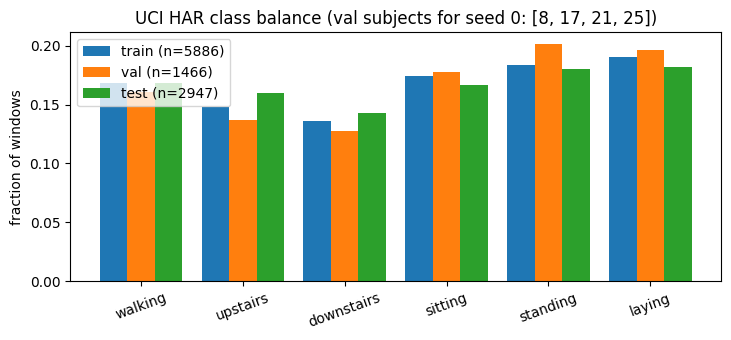

In [ ]:
DATA = "../data"
HAR_ROOT = f"{DATA}/har/UCI HAR Dataset"
CHANNELS = ["body_acc_x","body_acc_y","body_acc_z","body_gyro_x","body_gyro_y","body_gyro_z",
            "total_acc_x","total_acc_y","total_acc_z"]
CLASS_NAMES = ["walking","upstairs","downstairs","sitting","standing","laying"]

def download_har():
    if os.path.isdir(HAR_ROOT): return
    os.makedirs(f"{DATA}/har", exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
    urllib.request.urlretrieve(url, f"{DATA}/har.zip")
    zipfile.ZipFile(f"{DATA}/har.zip").extractall(f"{DATA}/har")
    inner = f"{DATA}/har/UCI HAR Dataset.zip"            # the archive may hold a second zip
    if os.path.exists(inner): zipfile.ZipFile(inner).extractall(f"{DATA}/har")
    assert os.path.isdir(HAR_ROOT), "HAR folder not found after extraction"

def load_har_split(split):
    X = np.stack([np.loadtxt(f"{HAR_ROOT}/{split}/Inertial Signals/{c}_{split}.txt") for c in CHANNELS],
                 axis=-1).astype(np.float32)                         # (N, 128, 9)
    y = np.loadtxt(f"{HAR_ROOT}/{split}/y_{split}.txt", dtype=int) - 1   # labels 0..5
    s = np.loadtxt(f"{HAR_ROOT}/{split}/subject_{split}.txt", dtype=int)
    return X, y, s

download_har()
X_TR_ALL, Y_TR_ALL, S_TR_ALL = load_har_split("train")
X_TE, Y_TE, S_TE = load_har_split("test")
print(X_TR_ALL.shape, X_TE.shape, "| train subjects:", len(np.unique(S_TR_ALL)), "test subjects:", len(np.unique(S_TE)))
assert X_TR_ALL.shape == (7352, 128, 9) and X_TE.shape == (2947, 128, 9)
assert not set(S_TR_ALL) & set(S_TE)                                  # subject sets do not overlap

def get_har(seed):
    """Subject-wise split: hold out 4 of the 21 training subjects; stats from the training part only."""
    rng = np.random.default_rng(seed)
    val_subj = rng.choice(np.unique(S_TR_ALL), 4, replace=False)
    is_val = np.isin(S_TR_ALL, val_subj)
    Xtr, ytr, Xva, yva = X_TR_ALL[~is_val], Y_TR_ALL[~is_val], X_TR_ALL[is_val], Y_TR_ALL[is_val]
    mean = Xtr.mean(axis=(0, 1), keepdims=True)                       # per channel, (1,1,9)
    std = Xtr.std(axis=(0, 1), keepdims=True) + 1e-8
    nrm = lambda a: ((a - mean) / std).astype(np.float32)
    return {"train": (nrm(Xtr), ytr), "val": (nrm(Xva), yva), "test": (nrm(X_TE), Y_TE), "val_subjects": val_subj}

def har_to_device(d):
    f = lambda p: (torch.tensor(p[0]).to(device), torch.tensor(p[1]).long().to(device))
    return f(d["train"]), f(d["val"]), f(d["test"])

d0 = get_har(SEEDS[0])
# sanity: normalisation used training statistics only
assert abs(d0["train"][0].mean()) < 1e-3
assert not set(S_TR_ALL[np.isin(S_TR_ALL, d0["val_subjects"])]) & set(S_TR_ALL[~np.isin(S_TR_ALL, d0["val_subjects"])])

# class-balance figure
fig, ax = plt.subplots(figsize=(7.5, 3.5)); w = 0.27
for j, name in enumerate(["train", "val", "test"]):
    cnt = np.bincount(d0[name][1], minlength=6)
    ax.bar(np.arange(6) + (j - 1) * w, cnt / cnt.sum(), w, label=f"{name} (n={cnt.sum()})")
ax.set_xticks(range(6)); ax.set_xticklabels(CLASS_NAMES, rotation=20); ax.set_ylabel("fraction of windows")
ax.set_title(f"UCI HAR class balance (val subjects for seed {SEEDS[0]}: {sorted(d0['val_subjects'].tolist())})")
ax.legend(); plt.tight_layout(); plt.savefig("figures/class_balance.png", dpi=150); plt.show()

In [ ]:
# ---- adding problem (function as per the assignment) ----
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

def test_adding(x, y):
    n, T, _ = x.shape
    m = x[:, :, 1]
    assert np.all(m.sum(1) == 2), "every sequence needs exactly two markers"
    assert np.all(m[:, : T // 2].sum(1) == 1) and np.all(m[:, T // 2:].sum(1) == 1), "one marker per half"
    assert np.allclose((x[:, :, 0] * m).sum(1), y, atol=1e-6), "target must be the sum of the marked values"

for T in ADD_LENGTHS:
    for n, sd in [(N_ADD_TRAIN, 0), (1000, 1), (1000, 2)]:
        test_adding(*make_adding(n, T, sd))
print("adding-problem generator tests passed; constant-1.0 baseline MSE =",
      round(float(np.mean((make_adding(1000, 100, 2)[1] - 1.0) ** 2)), 4))

_ADD_CACHE = {}
def get_adding(T):
    if T not in _ADD_CACHE:
        sp = [make_adding(N_ADD_TRAIN, T, 0), make_adding(1000, T, 1), make_adding(1000, T, 2)]
        _ADD_CACHE[T] = [(torch.tensor(x).to(device), torch.tensor(y).to(device)) for x, y in sp]
    return _ADD_CACHE[T]

adding-problem generator tests passed; constant-1.0 baseline MSE = 0.1697


## Task 2 - Cells from scratch
Implemented below with only tensor ops (`@`, `torch.tanh`, `torch.sigmoid`, ...).
Conventions the tests below rely on:
* parameters named `W_ih` (G*h, d), `W_hh` (G*h, h), `b` (G*h,) with ONE bias vector (this gives your hand counts 4,736 / 18,944 / 14,208);
* gates stacked in PyTorch's order: LSTM `i, f, g, o`; GRU `r, z, n`;
* attributes `W_hh.shape[1]` gives the hidden size.

Equations (x: (B,d), h: (B,h)):
* RNN: `h' = tanh(x W_ih^T + h W_hh^T + b)`
* LSTM: `[i,f,g,o] = x W_ih^T + h W_hh^T + b` (chunk into 4), `c' = sigmoid(f)*c + sigmoid(i)*tanh(g)`, `h' = sigmoid(o)*tanh(c')`
* GRU: `gi = x W_ih^T + b`, `gh = h W_hh^T`, `r = sigmoid(gi_r + gh_r)`, `z = sigmoid(gi_z + gh_z)`, `n = tanh(gi_n + r*gh_n)`, `h' = (1-z)*n + z*h`

Note on the bias: PyTorch keeps `b_ih` and `b_hh`. With one bias, the GRU `n` gate cannot be matched by merging them (`r` multiplies `b_hn`),
so the test copies **your** weights into the library layer with `bias_ih = b, bias_hh = 0` (equivalent evidence to copying the other way).

In [ ]:
class MyRNNCell(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        k = 1.0 / math.sqrt(h)
        self.W_ih = nn.Parameter(torch.empty(h, d).uniform_(-k, k))
        self.W_hh = nn.Parameter(torch.empty(h, h).uniform_(-k, k))
        self.b = nn.Parameter(torch.empty(h).uniform_(-k, k))
    def forward(self, x, h):                       # x (B,d), h (B,h) -> (B,h)
        return torch.tanh(x @ self.W_ih.T + h @ self.W_hh.T + self.b)

class MyLSTMCell(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        k = 1.0 / math.sqrt(h)
        self.W_ih = nn.Parameter(torch.empty(4 * h, d).uniform_(-k, k))     # gate order i, f, g, o
        self.W_hh = nn.Parameter(torch.empty(4 * h, h).uniform_(-k, k))
        self.b = nn.Parameter(torch.empty(4 * h).uniform_(-k, k))
    def forward(self, x, state):
        h, c = state
        i, f, g, o = (x @ self.W_ih.T + h @ self.W_hh.T + self.b).chunk(4, dim=-1)
        c_new = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h_new = torch.sigmoid(o) * torch.tanh(c_new)
        return h_new, c_new

class MyGRUCell(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        k = 1.0 / math.sqrt(h)
        self.W_ih = nn.Parameter(torch.empty(3 * h, d).uniform_(-k, k))     # gate order r, z, n
        self.W_hh = nn.Parameter(torch.empty(3 * h, h).uniform_(-k, k))
        self.b = nn.Parameter(torch.empty(3 * h).uniform_(-k, k))
    def forward(self, x, h):
        i_r, i_z, i_n = (x @ self.W_ih.T + self.b).chunk(3, dim=-1)
        h_r, h_z, h_n = (h @ self.W_hh.T).chunk(3, dim=-1)
        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)               # reset gate multiplies the recurrent part only
        return (1 - z) * n + z * h

In [ ]:
def run_cell_over_time(cell, x, kind):
    """Unroll a cell over x: (B,T,d) -> all hidden states (B,T,h). Zero initial state."""
    B, T, _ = x.shape
    H = cell.W_hh.shape[1]
    h = x.new_zeros(B, H)
    state = (h, x.new_zeros(B, H)) if kind == "lstm" else h
    outs = []
    for t in range(T):
        state = cell(x[:, t], state)
        outs.append(state[0] if kind == "lstm" else state)
    return torch.stack(outs, dim=1)

CELLS = {"rnn": (MyRNNCell, nn.RNN, 1), "lstm": (MyLSTMCell, nn.LSTM, 4), "gru": (MyGRUCell, nn.GRU, 3)}

def check_against_library(kind, d=9, h=64, B=5, T=20):
    torch.manual_seed(0)
    mine_cls, lib_cls, _ = CELLS[kind]
    mine, lib = mine_cls(d, h), lib_cls(d, h, batch_first=True)
    with torch.no_grad():
        lib.weight_ih_l0.copy_(mine.W_ih); lib.weight_hh_l0.copy_(mine.W_hh)
        lib.bias_ih_l0.copy_(mine.b);      lib.bias_hh_l0.zero_()
    x = torch.randn(B, T, d)
    with torch.no_grad():
        out_lib, _ = lib(x)
        out_mine = run_cell_over_time(mine, x, kind)
    err = (out_lib - out_mine).abs().max().item()
    assert err < 1e-5, f"{kind}: max abs diff {err}"
    return err, sum(p.numel() for p in mine.parameters()), sum(p.numel() for p in lib.parameters())

rows = []
for kind in ["rnn", "lstm", "gru"]:
    err, mine_n, lib_n = check_against_library(kind)
    rows.append({"cell": kind, "max_abs_err": err, "my_params": mine_n, "torch_params": lib_n})
pc = pd.DataFrame(rows); print(pc)
assert pc.my_params.tolist() == [4736, 18944, 14208] and pc.torch_params.tolist() == [4800, 19200, 14400]

   cell   max_abs_err  my_params  torch_params
0   rnn  1.490116e-07       4736          4800
1  lstm  5.960464e-08      18944         19200
2   gru  5.960464e-08      14208         14400


**Hand derivation (d = 9, h = 64)** - one block per gate has `h*d + h*h + h = 576 + 4096 + 64 = 4,736` parameters.
RNN: 1 block = 4,736. LSTM: 4 blocks (i,f,g,o) = 18,944. GRU: 3 blocks (r,z,n) = 14,208.
PyTorch stores a second bias vector `b_hh` per gate block: +64, +256, +192 -> 4,800, 19,200, 14,400. The extra bias is redundant for RNN/LSTM
(the two add up) and is the separate `b_hn` inside the reset gate for the GRU.

## Models and training utilities (library layers are allowed from here on)

In [ ]:
class SeqModel(nn.Module):
    """Library recurrent layer + linear head on the LAST hidden state."""
    def __init__(self, kind, d_in, hidden, d_out):
        super().__init__()
        self.rnn = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind](d_in, hidden, batch_first=True)
        self.head = nn.Linear(hidden, d_out)
    def forward(self, x, return_seq=False):
        out, _ = self.rnn(x)                       # (B,T,H)
        y = self.head(out[:, -1])                  # (B,d_out)
        return (y, out) if return_seq else y

def n_params(m): return sum(p.numel() for p in m.parameters())

def set_forget_bias(lstm, value):
    """Total forget-gate bias = value (PyTorch gate order i,f,g,o -> chunk 1)."""
    h = lstm.hidden_size
    with torch.no_grad():
        lstm.bias_ih_l0[h:2 * h] = value
        lstm.bias_hh_l0[h:2 * h] = 0.0

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval()
    return torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])

@torch.no_grad()
def mse_of(model, x, y, bs=1000):
    model.eval()
    se = sum(((model(x[i:i + bs]).squeeze(-1) - y[i:i + bs]) ** 2).sum().item() for i in range(0, len(x), bs))
    return se / len(x)

## Task 3 - HAR classification (same budget for RNN / LSTM / GRU)

rnn   seed 0: acc 0.8602  F1 0.8571  0.29s/ep
rnn   seed 1: acc 0.8456  F1 0.8440  0.28s/ep
rnn   seed 2: acc 0.8588  F1 0.8575  0.23s/ep
lstm  seed 0: acc 0.9209  F1 0.9209  0.25s/ep
lstm  seed 1: acc 0.8887  F1 0.8892  0.26s/ep
lstm  seed 2: acc 0.8873  F1 0.8877  0.47s/ep
gru   seed 0: acc 0.9033  F1 0.9040  0.30s/ep
gru   seed 1: acc 0.8914  F1 0.8913  0.25s/ep
gru   seed 2: acc 0.8918  F1 0.8911  0.23s/ep
       acc_mean  acc_std  f1_mean  f1_std  params  sec_per_epoch
model                                                           
gru      0.8955   0.0068   0.8955  0.0074   14790         0.2607
lstm     0.8990   0.0190   0.8993  0.0187   19590         0.3256
rnn      0.8549   0.0081   0.8529  0.0077    5190         0.2679


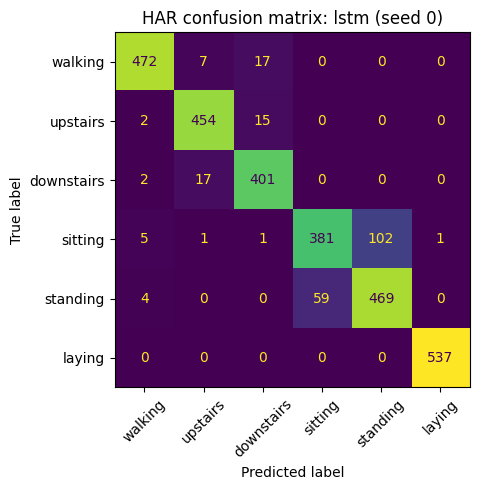

In [ ]:
def train_har(kind, seed, hidden=None, epochs=None):
    hidden = hidden or HIDDEN; epochs = epochs or EPOCHS_HAR
    set_seed(seed)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = har_to_device(get_har(seed))
    model = SeqModel(kind, 9, hidden, 6).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    best_val, best_state, times = -1, None, []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)       # same clipping for all three
            opt.step()
        sync(); times.append(time.time() - t0)
        val_acc = (predict(model, Xva) == yva).float().mean().item()
        if val_acc > best_val:
            best_val = val_acc; best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)                                 # model selection on validation only
    pred = predict(model, Xte).cpu().numpy(); y = yte.cpu().numpy()
    return {"test_acc": float((pred == y).mean()), "macro_f1": float(f1_score(y, pred, average="macro")),
            "params": n_params(model), "sec_per_epoch": float(np.mean(times)),
            "val_acc": best_val, "pred": pred, "y": y}

har_runs = {}
for kind in ["rnn", "lstm", "gru"]:
    for seed in SEEDS:
        r = train_har(kind, seed); har_runs[(kind, seed)] = r
        log_result(problem="P1-HAR", model=kind, seed=seed, seq_len=128, test_acc=r["test_acc"], macro_f1=r["macro_f1"],
                   params=r["params"], sec_per_epoch=r["sec_per_epoch"], notes=f"hidden={HIDDEN};epochs={EPOCHS_HAR};clip={CLIP}")
        print(f"{kind:5s} seed {seed}: acc {r['test_acc']:.4f}  F1 {r['macro_f1']:.4f}  {r['sec_per_epoch']:.2f}s/ep")

df = pd.read_csv(RESULTS_CSV); har = df[df.problem == "P1-HAR"]
summary = har.groupby("model").agg(acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
                                   f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
                                   params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean")).round(4)
print(summary)

# confusion matrix of the best model (best kind by mean test accuracy; its run with the highest validation accuracy)
best_kind = summary.acc_mean.idxmax()
best_seed = max(SEEDS, key=lambda s: har_runs[(best_kind, s)]["val_acc"])
r = har_runs[(best_kind, best_seed)]
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(r["y"], r["pred"]), display_labels=CLASS_NAMES).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f"HAR confusion matrix: {best_kind} (seed {best_seed})"); plt.tight_layout()
plt.savefig("figures/har_confusion.png", dpi=150); plt.show()

## Task 4 - Adding problem (T = 50, 100, 200, 400)

T= 50 rnn   seed 0: test MSE 0.0172
T= 50 rnn   seed 1: test MSE 0.0105
T= 50 rnn   seed 2: test MSE 0.1694
T= 50 lstm  seed 0: test MSE 0.0004
T= 50 lstm  seed 1: test MSE 0.0002
T= 50 lstm  seed 2: test MSE 0.0003
T= 50 gru   seed 0: test MSE 0.0001
T= 50 gru   seed 1: test MSE 0.0001
T= 50 gru   seed 2: test MSE 0.0001
T=100 rnn   seed 0: test MSE 0.1691
T=100 rnn   seed 1: test MSE 0.1667
T=100 rnn   seed 2: test MSE 0.1696
T=100 lstm  seed 0: test MSE 0.0021
T=100 lstm  seed 1: test MSE 0.0032
T=100 lstm  seed 2: test MSE 0.0028
T=100 gru   seed 0: test MSE 0.0001
T=100 gru   seed 1: test MSE 0.0002
T=100 gru   seed 2: test MSE 0.0001
T=200 rnn   seed 0: test MSE 0.1687
T=200 rnn   seed 1: test MSE 0.1685
T=200 rnn   seed 2: test MSE 0.1687
T=200 lstm  seed 0: test MSE 0.0621
T=200 lstm  seed 1: test MSE 0.1683
T=200 lstm  seed 2: test MSE 0.1672
T=200 gru   seed 0: test MSE 0.0003
T=200 gru   seed 1: test MSE 0.0002
T=200 gru   seed 2: test MSE 0.0003
T=400 rnn   seed 0: test MSE

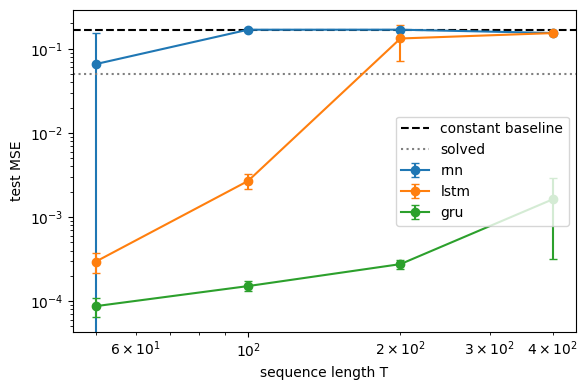

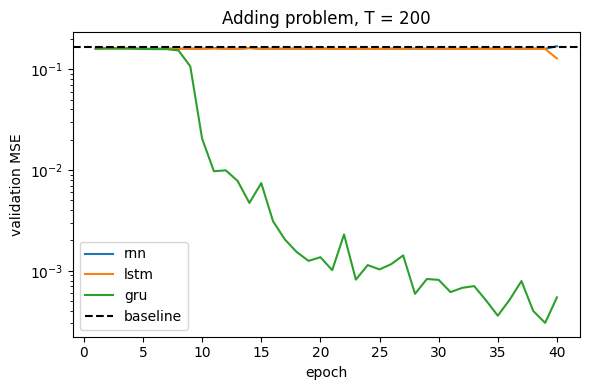

In [ ]:
def train_adding(kind, T, seed, hidden=None, epochs=None, clip=CLIP, forget_bias=None, return_model=False):
    hidden = hidden or HIDDEN; epochs = epochs or EPOCHS_ADD
    set_seed(seed)
    (xtr, ytr), (xva, yva), (xte, yte) = get_adding(T)
    model = SeqModel(kind, 2, hidden, 1).to(device)
    if forget_bias is not None:
        assert kind == "lstm"; set_forget_bias(model.rnn, forget_bias)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    tr_curve, va_curve, times = [], [], []
    best_val, best_state = float("inf"), None
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time()
        perm = torch.randperm(len(xtr), device=device); run = torch.zeros((), device=device)
        for i in range(0, len(xtr), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.mse_loss(model(xtr[idx]).squeeze(-1), ytr[idx])
            opt.zero_grad(); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); run += loss.detach() * len(idx)
        sync(); times.append(time.time() - t0)
        tr_curve.append(run.item() / len(xtr)); v = mse_of(model, xva, yva); va_curve.append(v)
        if v < best_val:
            best_val = v; best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    out = {"test_mse": mse_of(model, xte, yte), "params": n_params(model), "sec_per_epoch": float(np.mean(times)),
           "train_curve": tr_curve, "val_curve": va_curve}
    if return_model: out["model"] = model
    return out

add_runs = {}
for T in ADD_LENGTHS:
    for kind in ["rnn", "lstm", "gru"]:
        for seed in SEEDS:
            r = train_adding(kind, T, seed); add_runs[(kind, T, seed)] = r
            log_result(problem="P1-adding", model=kind, seed=seed, seq_len=T, test_mse=r["test_mse"], params=r["params"],
                       sec_per_epoch=r["sec_per_epoch"], notes=f"hidden={HIDDEN};epochs={EPOCHS_ADD};clip={CLIP}")
            print(f"T={T:3d} {kind:5s} seed {seed}: test MSE {r['test_mse']:.4f}")

df = pd.read_csv(RESULTS_CSV); add = df[df.problem == "P1-adding"].copy()
tab = add.groupby(["seq_len", "model"]).test_mse.agg(["mean", "std"]).round(4); print(tab)
solved = add.assign(solved=add.test_mse < 0.05).groupby(["seq_len", "model"]).solved.agg(
    lambda s: f"{int(s.sum())}/{len(s)}").unstack()
print("\nSolved runs (test MSE < 0.05) - baseline MSE ~ 0.167:\n", solved)

# MSE vs T
fig, ax = plt.subplots(figsize=(6, 4))
for kind in ["rnn", "lstm", "gru"]:
    g = add[add.model == kind].groupby("seq_len").test_mse
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().fillna(0).values, marker="o", capsize=3, label=kind)
ax.axhline(0.167, color="k", ls="--", label="constant baseline"); ax.axhline(0.05, color="gray", ls=":", label="solved")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("sequence length T"); ax.set_ylabel("test MSE")
ax.legend(); plt.tight_layout(); plt.savefig("figures/adding_mse_vs_T.png", dpi=150); plt.show()

# learning curves at T = 200 (mean over seeds)
fig, ax = plt.subplots(figsize=(6, 4))
for kind in ["rnn", "lstm", "gru"]:
    c = np.mean([add_runs[(kind, 200, s)]["val_curve"] for s in SEEDS], axis=0)
    ax.plot(range(1, len(c) + 1), c, label=kind)
ax.axhline(0.167, color="k", ls="--", label="baseline"); ax.set_yscale("log")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE"); ax.set_title("Adding problem, T = 200")
ax.legend(); plt.tight_layout(); plt.savefig("figures/adding_curves_T200.png", dpi=150); plt.show()

## Task 5(a) - Gradient norm ||dL/dh_t|| against t (T = 100), before and after training

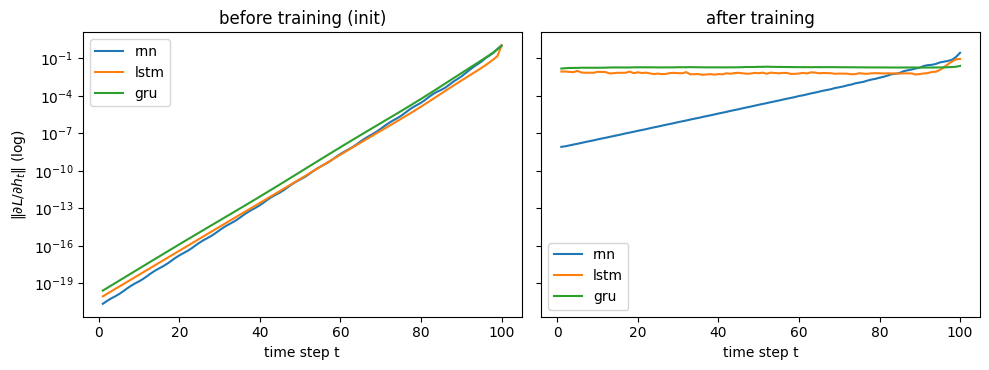

In [27]:
def grad_norms_per_step(model, kind, T=100, n=256):
    """Mean over n validation sequences of ||dL_b/dh_t||, t = 1..T (per-sample loss).
    The trained library layer is unrolled step by step with the matching *Cell class (same weights), so each h_t is
    a tensor in the autograd graph and receives a real gradient (a fused nn.RNN/LSTM/GRU layer hides its inner states)."""
    x, y = get_adding(T)[1]; x, y = x[:n], y[:n]
    r = model.rnn; H = r.hidden_size
    cell = {"rnn": nn.RNNCell, "lstm": nn.LSTMCell, "gru": nn.GRUCell}[kind](2, H).to(device)
    with torch.no_grad():
        cell.weight_ih.copy_(r.weight_ih_l0); cell.weight_hh.copy_(r.weight_hh_l0)
        cell.bias_ih.copy_(r.bias_ih_l0);     cell.bias_hh.copy_(r.bias_hh_l0)
    h = x.new_zeros(n, H); c = x.new_zeros(n, H); hs = []
    for t in range(T):
        if kind == "lstm": h, c = cell(x[:, t], (h, c))
        else: h = cell(x[:, t], h)
        h.retain_grad(); hs.append(h)
    loss = ((model.head(hs[-1]).squeeze(-1) - y) ** 2).sum()      # sum of per-sample losses
    loss.backward()
    return torch.stack([hh.grad.norm(dim=-1).mean() for hh in hs]).detach().cpu().numpy()   # (T,)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for kind in ["rnn", "lstm", "gru"]:
    set_seed(SEEDS[0])
    g0 = grad_norms_per_step(SeqModel(kind, 2, HIDDEN, 1).to(device), kind)
    trained = train_adding(kind, 100, SEEDS[0], return_model=True)["model"]
    g1 = grad_norms_per_step(trained, kind)
    axes[0].semilogy(range(1, 101), g0 + 1e-30, label=kind); axes[1].semilogy(range(1, 101), g1 + 1e-30, label=kind)
for ax, ttl in zip(axes, ["before training (init)", "after training"]):
    ax.set_title(ttl); ax.set_xlabel("time step t"); ax.legend()
axes[0].set_ylabel(r"$\|\partial L/\partial h_t\|$ (log)"); plt.tight_layout()
plt.savefig("figures/gradient_norms_T100.png", dpi=150); plt.show()

## Task 5(b) - Hidden-size sweep for LSTM and GRU on HAR

              acc_mean  acc_std  params  sec_per_epoch
model hidden                                          
gru   16        0.8807   0.0122    1398         0.2281
      32        0.8912   0.0070    4326         0.2377
      64        0.8955   0.0068   14790         0.2378
      128       0.9034   0.0110   54150         0.2345
lstm  16        0.8755   0.0137    1830         0.2845
      32        0.8755   0.0116    5702         0.2462
      64        0.8990   0.0190   19590         0.2471
      128       0.9036   0.0126   71942         0.3198


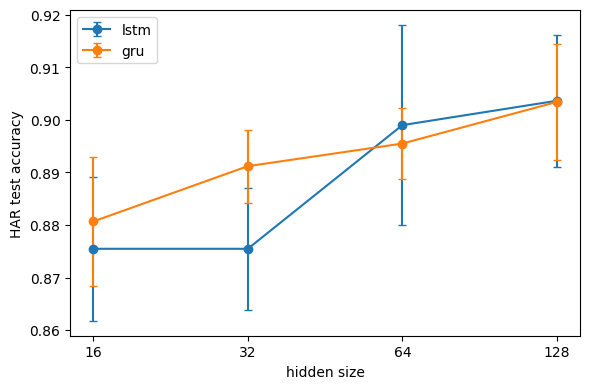

In [ ]:
SWEEP = [16, 32, 64, 128]
for kind in ["lstm", "gru"]:
    for h in SWEEP:
        for seed in SEEDS:
            r = train_har(kind, seed, hidden=h)
            log_result(problem="P1-sweep", model=kind, seed=seed, seq_len=128, test_acc=r["test_acc"], macro_f1=r["macro_f1"],
                       params=r["params"], sec_per_epoch=r["sec_per_epoch"], notes=f"hidden={h};epochs={EPOCHS_HAR}")
df = pd.read_csv(RESULTS_CSV); sw = df[df.problem == "P1-sweep"].copy()
sw["hidden"] = sw.notes.str.extract(r"hidden=(\d+)").astype(int)
sw_tab = sw.groupby(["model", "hidden"]).agg(acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
                                              params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean")).round(4)
print(sw_tab)
fig, ax = plt.subplots(figsize=(6, 4))
for kind in ["lstm", "gru"]:
    g = sw[sw.model == kind].groupby("hidden").test_acc
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().fillna(0).values, marker="o", capsize=3, label=kind)
ax.set_xscale("log", base=2); ax.set_xticks(SWEEP); ax.set_xticklabels(SWEEP)
ax.set_xlabel("hidden size"); ax.set_ylabel("HAR test accuracy"); ax.legend(); plt.tight_layout()
plt.savefig("figures/hidden_size_sweep.png", dpi=150); plt.show()

## Task 5(c) - Individual ablation (T = 200)
even last digit: gradient clipping (1.0 vs none) for the vanilla RNN; odd: LSTM forget-gate bias 0 vs 1.

ablation: lstm ['forget bias 0', 'forget bias 1']
forget bias 0  seed 0: test MSE 0.1685
forget bias 0  seed 1: test MSE 0.1683
forget bias 0  seed 2: test MSE 0.0221
forget bias 1  seed 0: test MSE 0.1685
forget bias 1  seed 1: test MSE 0.1684
forget bias 1  seed 2: test MSE 0.0171
                           mean     std
notes                                  
forget bias 0;epochs=40  0.1197  0.0845
forget bias 1;epochs=40  0.1180  0.0874


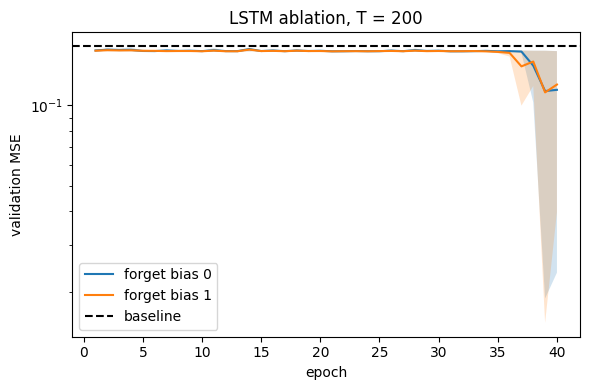

In [ ]:
if ID_LAST_DIGIT % 2 == 0:
    ABL_KIND = "rnn"; ABL = [("clip 1.0", dict(clip=1.0)), ("no clip", dict(clip=None))]
else:
    ABL_KIND = "lstm"; ABL = [("forget bias 0", dict(forget_bias=0.0)), ("forget bias 1", dict(forget_bias=1.0))]
print("ablation:", ABL_KIND, [a[0] for a in ABL])

abl_runs = {}
for label, kw in ABL:
    for seed in SEEDS:
        r = train_adding(ABL_KIND, 200, seed, **kw); abl_runs[(label, seed)] = r
        log_result(problem="P1-ablation", model=ABL_KIND, seed=seed, seq_len=200, test_mse=r["test_mse"], params=r["params"],
                   sec_per_epoch=r["sec_per_epoch"], notes=f"{label};epochs={EPOCHS_ADD}")
        print(f"{label:14s} seed {seed}: test MSE {r['test_mse']:.4f}")
print(pd.read_csv(RESULTS_CSV).query("problem == 'P1-ablation'").groupby("notes").test_mse.agg(["mean", "std"]).round(4))

fig, ax = plt.subplots(figsize=(6, 4))
for label, _ in ABL:
    c = np.array([abl_runs[(label, s)]["val_curve"] for s in SEEDS])
    ax.plot(range(1, c.shape[1] + 1), c.mean(0), label=label)
    ax.fill_between(range(1, c.shape[1] + 1), c.min(0), c.max(0), alpha=0.2)
ax.axhline(0.167, color="k", ls="--", label="baseline"); ax.set_yscale("log")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE"); ax.set_title(f"{ABL_KIND.upper()} ablation, T = 200")
ax.legend(); plt.tight_layout(); plt.savefig("figures/ablation_5c.png", dpi=150); plt.show()

## Task 5(d) - Analysis (write in the report)
Tables to quote: HAR `summary` (accuracy, parameters, sec/epoch), the adding-problem `tab` and `solved`, the gradient plot, `sw_tab`, and the ablation table.

In [12]:
import os
print("cwd:", os.getcwd())
print("results.csv:", os.path.abspath("../results.csv"), os.path.exists("../results.csv"))
print("figures:", os.listdir("figures"))

cwd: /content
results.csv: /results.csv True
figures: ['adding_mse_vs_T.png', 'ablation_5c.png', 'gradient_norms_T100.png', 'har_confusion.png', 'class_balance.png', 'hidden_size_sweep.png', 'adding_curves_T200.png']


In [28]:
import shutil
from google.colab import files
shutil.copy("../results.csv", "results_problem1.csv")
shutil.make_archive("problem1_figures", "zip", "figures")
files.download("results_problem1.csv")
files.download("problem1_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>